## WOS46985_RESULT

In [2]:
import json
from pathlib import Path

RESULTS_DIR = Path("WOS46985_RESULTS")

with open(RESULTS_DIR / "results_simple.json", encoding="utf-8") as f:
    data = json.load(f)

print("Top-level keys:")
print(list(data.keys())[:10])

print("\nFirst completed sample:")
for key, value in data.items():
    if isinstance(value, dict):
        print("Sample ID:", key)
        print(json.dumps(value, indent=2, ensure_ascii=False)[:3000])
        break

Top-level keys:
['mixtral_30_0.0', '23329_mixtral_30_1_0.0_0.0', '7103_mixtral_30_1_0.0_0.0', '25733_mixtral_30_1_0.0_0.0', '9237_mixtral_30_1_0.0_0.0', '31983_mixtral_30_1_0.0_0.0', '23112_mixtral_30_1_0.0_0.0', '40776_mixtral_30_1_0.0_0.0', '19185_mixtral_30_1_0.0_0.0', '40098_mixtral_30_1_0.0_0.0']

First completed sample:
Sample ID: 23329_mixtral_30_1_0.0_0.0
{
  "id": "23329",
  "llm": "mixtral",
  "Q": 30,
  "A": 1,
  "target": "Biochemistry",
  "temp_question": 0.0,
  "temp_answer": 0.0,
  "entropy": 0.4699921720177474,
  "counts": [
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    3.0,
    27.0,
    0.0
  ],
  "distribution": [
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.1,
    0.9,
    0.0
  ],
  "info_answers": {
    "0": [
      "Biochemistry"
    ],
    "1": [
      "Biochemistry"
    ],
    "2": [
      "Biochemistry"
    ],
    "3": [
      "Biochemistry"
    ],
    "4": [
      "Biochemistry"
    ],
    "5": [
      "Biochemistry"
    ],
    "6": [
      "Biochemi

### Sensitivity

In [3]:
import numpy as np
import pandas as pd

strategies = ["simple", "instruct", "fewshot"]
sensitivity_results = []

for strategy in strategies:
    path = RESULTS_DIR / f"results_{strategy}.json"

    with open(path, encoding="utf-8") as f:
        data = json.load(f)

    sensitivities = []

    for sample in data.values():
        if not isinstance(sample, dict):
            continue

        p = np.array(sample["distribution"], dtype=float)

        # Equation 3: normalized entropy
        p_nonzero = p[p > 0]
        sensitivity = -np.sum(p_nonzero * np.log(p_nonzero)) / np.log(len(p))

        sensitivities.append(sensitivity)

    # Equation 4: average across samples
    mean_sensitivity = np.mean(sensitivities)

    sensitivity_results.append({
        "Strategy": strategy,
        "Samples": len(sensitivities),
        "Our sensitivity": mean_sensitivity
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

# Published Mixtral values from Table 1
published = {
    "simple": 0.112,
    "instruct": 0.124,
    "fewshot": 0.142
}

sensitivity_df["Paper sensitivity"] = (
    sensitivity_df["Strategy"].map(published)
)

sensitivity_df["Difference"] = (
    sensitivity_df["Our sensitivity"]
    - sensitivity_df["Paper sensitivity"]
)

display(sensitivity_df.round(4))

,Strategy,Samples,Our sensitivity,Paper sensitivity,Difference
0,simple,2000,0.1117,0.112,-0.0003
1,instruct,2000,0.1284,0.124,0.0044
2,fewshot,2000,0.1475,0.142,0.0055


**Sensitivity normalization.** The WoS dataset contains seven ground-truth classes, but the paper introduces an additional N/A class for invalid predictions. We therefore calculate normalized entropy using \(C=8\). The paper does not explicitly clarify this choice, but this interpretation produces results closer to the published values.

### Consistency

In [7]:
import numpy as np
import pandas as pd
import json

consistency_results = []

for strategy in strategies:
    with open(RESULTS_DIR / f"results_{strategy}.json", encoding="utf-8") as f:
        data = json.load(f)

    samples = [v for v in data.values() if isinstance(v, dict)]

    # group prediction distributions by ground-truth class
    classes = {}
    for sample in samples:
        target = sample["target"]
        distribution = np.array(sample["distribution"], dtype=float)
        classes.setdefault(target, []).append(distribution)

    # equations 5–7: average pairwise consistency within each class
    class_consistencies = {}
    total_consistency = 0.0
    total_pairs = 0

    for target, distributions in classes.items():
        P = np.stack(distributions)
        n = len(P)

        # compute pairwise total variation distance
        tvd = 0.5 * np.abs(
            P[:, None, :] - P[None, :, :]
        ).sum(axis=2)

        consistency = 1 - tvd

        # equation 7 includes all ordered pairs, including self-pairs
        class_consistencies[target] = consistency.mean()

        total_consistency += consistency.sum()
        total_pairs += n * n

    # weighted average across all within-class pairs
    mean_consistency = total_consistency / total_pairs

    consistency_results.append({
        "Strategy": strategy,
        "Our consistency": mean_consistency,
        "Paper consistency": {
            "simple": 0.483,
            "instruct": 0.469,
            "fewshot": 0.472
        }[strategy],
        "Pairs": total_pairs
    })

consistency_df = pd.DataFrame(consistency_results)

consistency_df["Difference"] = (
    consistency_df["Our consistency"]
    - consistency_df["Paper consistency"]
)

display(consistency_df.round(4))

,Strategy,Our consistency,Paper consistency,Pairs,Difference
0,simple,0.4845,0.483,571432,0.0015
1,instruct,0.4682,0.469,571432,-0.0008
2,fewshot,0.4756,0.472,571432,0.0036


### Micro-F1

In [8]:
from sklearn.metrics import f1_score

f1_results = []

paper_f1 = {
    "simple": 0.606,
    "instruct": 0.599,
    "fewshot": 0.566
}

for strategy in strategies:
    with open(RESULTS_DIR / f"results_{strategy}.json", encoding="utf-8") as f:
        data = json.load(f)

    y_true = []
    y_pred = []

    for sample in data.values():
        if not isinstance(sample, dict):
            continue

        target = sample["target"]

        for answers in sample["info_answers"].values():
            for prediction in answers:
                y_true.append(target)
                y_pred.append(prediction)

    micro_f1 = f1_score(y_true, y_pred, average="micro")

    f1_results.append({
        "Strategy": strategy,
        "Predictions": len(y_pred),
        "Our Micro-F1": micro_f1,
        "Paper Micro-F1": paper_f1[strategy],
        "Difference": micro_f1 - paper_f1[strategy]
    })

f1_df = pd.DataFrame(f1_results)

display(f1_df.round(4))

,Strategy,Predictions,Our Micro-F1,Paper Micro-F1,Difference
0,simple,60000,0.5945,0.606,-0.0115
1,instruct,60000,0.6020,0.599,0.0030
2,fewshot,60000,0.5492,0.566,-0.0168


Because WoS is a single-label multiclass classification task, micro-F1 is equivalent to accuracy when all classes, including invalid predictions, are accounted for.

In [9]:
f1_results = []

paper_f1 = {
    "simple": 0.606,
    "instruct": 0.599,
    "fewshot": 0.566
}

for strategy in strategies:
    with open(RESULTS_DIR / f"results_{strategy}.json", encoding="utf-8") as f:
        data = json.load(f)

    y_true = []
    y_pred = []

    for sample in data.values():
        if not isinstance(sample, dict):
            continue

        for answers in sample["info_answers"].values():
            for prediction in answers:
                y_true.append(sample["target"])
                y_pred.append(prediction)

    # include every class appearing in true or predicted labels
    classes = set(y_true) | set(y_pred)

    TP = FP = FN = 0

    for c in classes:
        TP += sum(t == c and p == c for t, p in zip(y_true, y_pred))
        FP += sum(t != c and p == c for t, p in zip(y_true, y_pred))
        FN += sum(t == c and p != c for t, p in zip(y_true, y_pred))

    # micro-precision and micro-recall
    precision = TP / (TP + FP)
    recall = TP / (TP + FN)

    # micro-F1
    micro_f1 = 2 * precision * recall / (precision + recall)

    f1_results.append({
        "Strategy": strategy,
        "Predictions": len(y_pred),
        "Our Micro-F1": micro_f1,
        "Paper Micro-F1": paper_f1[strategy],
        "Difference": micro_f1 - paper_f1[strategy]
    })

f1_df = pd.DataFrame(f1_results)

display(f1_df.round(4))

,Strategy,Predictions,Our Micro-F1,Paper Micro-F1,Difference
0,simple,60000,0.5945,0.606,-0.0115
1,instruct,60000,0.6020,0.599,0.0030
2,fewshot,60000,0.5492,0.566,-0.0168


Consistant with the formula version from the paper.

## TREC

### Sensitivity

In [10]:
RESULTS_DIR = Path("TREC_RESULTS")

paper_sensitivity = {
    "simple": 0.223,
    "instruct": 0.182,
    "fewshot": 0.166
}

sensitivity_results = []

for strategy in strategies:
    with open(RESULTS_DIR / f"results_{strategy}.json", encoding="utf-8") as f:
        data = json.load(f)

    sensitivities = []

    for sample in data.values():
        if not isinstance(sample, dict):
            continue

        p = np.array(sample["distribution"], dtype=float)
        p_nonzero = p[p > 0]

        # Equation 3: normalized entropy
        sensitivity = (
            -np.sum(p_nonzero * np.log(p_nonzero))
            / np.log(len(p))
        )

        sensitivities.append(sensitivity)

    # Equation 4: mean sensitivity
    mean_sensitivity = np.mean(sensitivities)

    sensitivity_results.append({
        "Strategy": strategy,
        "Samples": len(sensitivities),
        "Our sensitivity": mean_sensitivity,
        "Paper sensitivity": paper_sensitivity[strategy],
        "Difference": mean_sensitivity - paper_sensitivity[strategy]
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(4))

,Strategy,Samples,Our sensitivity,Paper sensitivity,Difference
0,simple,500,0.1906,0.223,-0.0324
1,instruct,500,0.1919,0.182,0.0099
2,fewshot,500,0.1429,0.166,-0.0231


### consistancy

In [11]:
paper_consistency = {
    "simple": 0.657,
    "instruct": 0.709,
    "fewshot": 0.640
}

consistency_results = []

for strategy in strategies:
    with open(RESULTS_DIR / f"results_{strategy}.json", encoding="utf-8") as f:
        data = json.load(f)

    samples = [v for v in data.values() if isinstance(v, dict)]

    classes = {}

    for sample in samples:
        target = sample["target"]
        distribution = np.array(sample["distribution"], dtype=float)
        classes.setdefault(target, []).append(distribution)

    total_consistency = 0.0
    total_pairs = 0

    for target, distributions in classes.items():
        P = np.stack(distributions)
        n = len(P)

        # Equation 5: Total Variation Distance
        tvd = 0.5 * np.abs(
            P[:, None, :] - P[None, :, :]
        ).sum(axis=2)

        # Equation 6: Pairwise consistency
        consistency = 1 - tvd

        # Equation 7: All ordered pairs, including self-pairs
        total_consistency += consistency.sum()
        total_pairs += n * n

    mean_consistency = total_consistency / total_pairs

    consistency_results.append({
        "Strategy": strategy,
        "Our consistency": mean_consistency,
        "Paper consistency": paper_consistency[strategy],
        "Pairs": total_pairs
    })

consistency_df = pd.DataFrame(consistency_results)

consistency_df["Difference"] = (
    consistency_df["Our consistency"]
    - consistency_df["Paper consistency"]
)

display(consistency_df.round(4))

,Strategy,Our consistency,Paper consistency,Pairs,Difference
0,simple,0.6566,0.657,51516,-0.0004
1,instruct,0.6834,0.709,51516,-0.0256
2,fewshot,0.6463,0.640,51516,0.0063


### Micro-F1

In [12]:
paper_f1 = {
    "simple": 0.736,
    "instruct": 0.728,
    "fewshot": 0.744
}

f1_results = []

for strategy in strategies:
    with open(RESULTS_DIR / f"results_{strategy}.json", encoding="utf-8") as f:
        data = json.load(f)

    y_true = []
    y_pred = []

    for sample in data.values():
        if not isinstance(sample, dict):
            continue

        for answers in sample["info_answers"].values():
            for prediction in answers:
                y_true.append(sample["target"])
                y_pred.append(prediction)

    classes = set(y_true) | set(y_pred)

    TP = FP = FN = 0

    for c in classes:
        TP += sum(t == c and p == c for t, p in zip(y_true, y_pred))
        FP += sum(t != c and p == c for t, p in zip(y_true, y_pred))
        FN += sum(t == c and p != c for t, p in zip(y_true, y_pred))

    # micro-precision
    precision = TP / (TP + FP)

    # micro-recall
    recall = TP / (TP + FN)

    # micro-F1
    micro_f1 = 2 * precision * recall / (precision + recall)

    f1_results.append({
        "Strategy": strategy,
        "Predictions": len(y_pred),
        "Our Micro-F1": micro_f1,
        "Paper Micro-F1": paper_f1[strategy],
        "Difference": micro_f1 - paper_f1[strategy]
    })

f1_df = pd.DataFrame(f1_results)

display(f1_df.round(4))

,Strategy,Predictions,Our Micro-F1,Paper Micro-F1,Difference
0,simple,15000,0.7294,0.736,-0.0066
1,instruct,15000,0.7056,0.728,-0.0224
2,fewshot,15000,0.7380,0.744,-0.0060


### CB

In [13]:
RESULTS_DIR = Path("CB_RESULTS")

### Sensitivity

In [14]:
RESULTS_DIR = Path("CB_RESULTS")

paper_sensitivity = {
    "simple": 0.203,
    "instruct": 0.013,
    "fewshot": 0.017
}

sensitivity_results = []

for strategy in strategies:
    with open(RESULTS_DIR / f"results_{strategy}.json", encoding="utf-8") as f:
        data = json.load(f)

    sensitivities = []

    for sample in data.values():
        if not isinstance(sample, dict):
            continue

        p = np.array(sample["distribution"], dtype=float)
        p_nonzero = p[p > 0]

        # Equation 3: normalized entropy
        sensitivity = (
            -np.sum(p_nonzero * np.log(p_nonzero))
            / np.log(len(p))
        )

        sensitivities.append(sensitivity)

    # Equation 4: average sensitivity across samples
    mean_sensitivity = np.mean(sensitivities)

    sensitivity_results.append({
        "Strategy": strategy,
        "Samples": len(sensitivities),
        "Our sensitivity": mean_sensitivity,
        "Paper sensitivity": paper_sensitivity[strategy],
        "Difference": mean_sensitivity - paper_sensitivity[strategy]
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(4))

,Strategy,Samples,Our sensitivity,Paper sensitivity,Difference
0,simple,250,0.2531,0.203,0.0501
1,instruct,250,0.1794,0.013,0.1664
2,fewshot,250,0.1847,0.017,0.1677


### Consistency

In [15]:
paper_consistency = {
    "simple": 0.625,
    "instruct": 0.695,
    "fewshot": 0.600
}

consistency_results = []

for strategy in strategies:
    with open(RESULTS_DIR / f"results_{strategy}.json", encoding="utf-8") as f:
        data = json.load(f)

    samples = [v for v in data.values() if isinstance(v, dict)]

    classes = {}

    for sample in samples:
        target = sample["target"]
        distribution = np.array(sample["distribution"], dtype=float)
        classes.setdefault(target, []).append(distribution)

    total_consistency = 0.0
    total_pairs = 0

    for target, distributions in classes.items():
        P = np.stack(distributions)
        n = len(P)

        # Equation 5: Total Variation Distance
        tvd = 0.5 * np.abs(
            P[:, None, :] - P[None, :, :]
        ).sum(axis=2)

        # Equation 6: Pairwise consistency
        consistency = 1 - tvd

        # Equation 7: All ordered pairs within each class
        total_consistency += consistency.sum()
        total_pairs += n * n

    mean_consistency = total_consistency / total_pairs

    consistency_results.append({
        "Strategy": strategy,
        "Our consistency": mean_consistency,
        "Paper consistency": paper_consistency[strategy],
        "Pairs": total_pairs,
        "Difference": mean_consistency - paper_consistency[strategy]
    })

consistency_df = pd.DataFrame(consistency_results)

display(consistency_df.round(4))

,Strategy,Our consistency,Paper consistency,Pairs,Difference
0,simple,0.5607,0.625,27642,-0.0643
1,instruct,0.6215,0.695,27642,-0.0735
2,fewshot,0.5591,0.600,27642,-0.0409


### Micro - F1

In [16]:
paper_f1 = {
    "simple": 0.672,
    "instruct": 0.788,
    "fewshot": 0.652
}

f1_results = []

for strategy in strategies:
    with open(RESULTS_DIR / f"results_{strategy}.json", encoding="utf-8") as f:
        data = json.load(f)

    y_true = []
    y_pred = []

    for sample in data.values():
        if not isinstance(sample, dict):
            continue

        for answers in sample["info_answers"].values():
            for prediction in answers:
                y_true.append(sample["target"])
                y_pred.append(prediction)

    classes = set(y_true) | set(y_pred)

    TP = FP = FN = 0

    for c in classes:
        TP += sum(t == c and p == c for t, p in zip(y_true, y_pred))
        FP += sum(t != c and p == c for t, p in zip(y_true, y_pred))
        FN += sum(t == c and p != c for t, p in zip(y_true, y_pred))

    # micro-precision
    precision = TP / (TP + FP)

    # micro-recall
    recall = TP / (TP + FN)

    # micro-F1
    micro_f1 = 2 * precision * recall / (precision + recall)

    f1_results.append({
        "Strategy": strategy,
        "Predictions": len(y_pred),
        "Our Micro-F1": micro_f1,
        "Paper Micro-F1": paper_f1[strategy],
        "Difference": micro_f1 - paper_f1[strategy]
    })

f1_df = pd.DataFrame(f1_results)

display(f1_df.round(4))

,Strategy,Predictions,Our Micro-F1,Paper Micro-F1,Difference
0,simple,7500,0.6001,0.672,-0.0719
1,instruct,7500,0.7032,0.788,-0.0848
2,fewshot,7500,0.6263,0.652,-0.0257


## RTE

In [17]:
RESULTS_DIR = Path("RTE_RESULTS")

paper_sensitivity = {
    "simple": 0.195,
    "instruct": 0.176,
    "fewshot": 0.046
}

sensitivity_results = []

for strategy in strategies:
    with open(RESULTS_DIR / f"results_{strategy}.json", encoding="utf-8") as f:
        data = json.load(f)

    sensitivities = []

    for sample in data.values():
        if not isinstance(sample, dict):
            continue

        p = np.array(sample["distribution"], dtype=float)
        p_nonzero = p[p > 0]

        # Equation 3: normalized entropy
        sensitivity = (
            -np.sum(p_nonzero * np.log(p_nonzero))
            / np.log(len(p))
        )

        sensitivities.append(sensitivity)

    # Equation 4: mean sensitivity across samples
    mean_sensitivity = np.mean(sensitivities)

    sensitivity_results.append({
        "Strategy": strategy,
        "Samples": len(sensitivities),
        "Our sensitivity": mean_sensitivity,
        "Paper sensitivity": paper_sensitivity[strategy],
        "Difference": mean_sensitivity - paper_sensitivity[strategy]
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(4))

,Strategy,Samples,Our sensitivity,Paper sensitivity,Difference
0,simple,2490,0.2599,0.195,0.0649
1,instruct,2490,0.0994,0.176,-0.0766
2,fewshot,2490,0.0601,0.046,0.0141


### Consistency

In [18]:
paper_consistency = {
    "simple": 0.669,
    "instruct": 0.676,
    "fewshot": 0.754
}

consistency_results = []

for strategy in strategies:
    with open(RESULTS_DIR / f"results_{strategy}.json", encoding="utf-8") as f:
        data = json.load(f)

    samples = [v for v in data.values() if isinstance(v, dict)]

    classes = {}

    for sample in samples:
        target = sample["target"]
        distribution = np.array(sample["distribution"], dtype=float)
        classes.setdefault(target, []).append(distribution)

    total_consistency = 0.0
    total_pairs = 0

    for target, distributions in classes.items():
        P = np.stack(distributions)
        n = len(P)

        # Equation 5: Total Variation Distance
        tvd = 0.5 * np.abs(
            P[:, None, :] - P[None, :, :]
        ).sum(axis=2)

        # Equation 6: Pairwise consistency
        consistency = 1 - tvd

        # Equation 7: All ordered pairs within each class
        total_consistency += consistency.sum()
        total_pairs += n * n

    mean_consistency = total_consistency / total_pairs

    consistency_results.append({
        "Strategy": strategy,
        "Our consistency": mean_consistency,
        "Paper consistency": paper_consistency[strategy],
        "Pairs": total_pairs,
        "Difference": mean_consistency - paper_consistency[strategy]
    })

consistency_df = pd.DataFrame(consistency_results)

display(consistency_df.round(4))

,Strategy,Our consistency,Paper consistency,Pairs,Difference
0,simple,0.5945,0.669,3100082,-0.0745
1,instruct,0.7511,0.676,3100082,0.0751
2,fewshot,0.7545,0.754,3100082,0.0005


### Micro -F1

In [19]:
paper_f1 = {
    "simple": 0.814,
    "instruct": 0.756,
    "fewshot": 0.847
}

f1_results = []

for strategy in strategies:
    with open(RESULTS_DIR / f"results_{strategy}.json", encoding="utf-8") as f:
        data = json.load(f)

    y_true = []
    y_pred = []

    for sample in data.values():
        if not isinstance(sample, dict):
            continue

        for answers in sample["info_answers"].values():
            for prediction in answers:
                y_true.append(sample["target"])
                y_pred.append(prediction)

    classes = set(y_true) | set(y_pred)

    TP = FP = FN = 0

    for c in classes:
        TP += sum(t == c and p == c for t, p in zip(y_true, y_pred))
        FP += sum(t != c and p == c for t, p in zip(y_true, y_pred))
        FN += sum(t == c and p != c for t, p in zip(y_true, y_pred))

    # micro-precision
    precision = TP / (TP + FP)

    # micro-recall
    recall = TP / (TP + FN)

    # micro-F1
    micro_f1 = 2 * precision * recall / (precision + recall)

    f1_results.append({
        "Strategy": strategy,
        "Predictions": len(y_pred),
        "Our Micro-F1": micro_f1,
        "Paper Micro-F1": paper_f1[strategy],
        "Difference": micro_f1 - paper_f1[strategy]
    })

f1_df = pd.DataFrame(f1_results)

display(f1_df.round(4))

,Strategy,Predictions,Our Micro-F1,Paper Micro-F1,Difference
0,simple,74700,0.6931,0.814,-0.1209
1,instruct,74700,0.8501,0.756,0.0941
2,fewshot,74700,0.8241,0.847,-0.0229


## DBPEDIA

In [20]:
RESULTS_DIR = Path("DBPEDIA_RESULTS")

paper_sensitivity = {
    "simple": 0.053,
    "instruct": 0.054,
    "fewshot": 0.069
}

### Sensitivity

In [21]:
sensitivity_results = []

for strategy in strategies:
    with open(RESULTS_DIR / f"results_{strategy}.json", encoding="utf-8") as f:
        data = json.load(f)

    sensitivities = []

    for sample in data.values():
        if not isinstance(sample, dict):
            continue

        p = np.array(sample["distribution"], dtype=float)
        p_nonzero = p[p > 0]

        # Equation 3: normalized entropy
        sensitivity = (
            -np.sum(p_nonzero * np.log(p_nonzero))
            / np.log(len(p))
        )

        sensitivities.append(sensitivity)

    # Equation 4: mean sensitivity across samples
    mean_sensitivity = np.mean(sensitivities)

    sensitivity_results.append({
        "Strategy": strategy,
        "Samples": len(sensitivities),
        "Our sensitivity": mean_sensitivity,
        "Paper sensitivity": paper_sensitivity[strategy],
        "Difference": mean_sensitivity - paper_sensitivity[strategy]
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(4))

,Strategy,Samples,Our sensitivity,Paper sensitivity,Difference
0,simple,2000,0.0494,0.053,-0.0036
1,instruct,2000,0.0537,0.054,-0.0003
2,fewshot,2000,0.0728,0.069,0.0038


### Consistency

In [22]:
paper_consistency = {
    "simple": 0.802,
    "instruct": 0.808,
    "fewshot": 0.773
}

consistency_results = []

for strategy in strategies:
    with open(RESULTS_DIR / f"results_{strategy}.json", encoding="utf-8") as f:
        data = json.load(f)

    samples = [v for v in data.values() if isinstance(v, dict)]

    classes = {}

    for sample in samples:
        target = sample["target"]
        distribution = np.array(sample["distribution"], dtype=float)
        classes.setdefault(target, []).append(distribution)

    total_consistency = 0.0
    total_pairs = 0

    for target, distributions in classes.items():
        P = np.stack(distributions)
        n = len(P)

        # Equation 5: Total Variation Distance
        tvd = 0.5 * np.abs(
            P[:, None, :] - P[None, :, :]
        ).sum(axis=2)

        # Equation 6: Pairwise consistency
        consistency = 1 - tvd

        # Equation 7: All ordered pairs within each class
        total_consistency += consistency.sum()
        total_pairs += n * n

    mean_consistency = total_consistency / total_pairs

    consistency_results.append({
        "Strategy": strategy,
        "Our consistency": mean_consistency,
        "Paper consistency": paper_consistency[strategy],
        "Pairs": total_pairs,
        "Difference": mean_consistency - paper_consistency[strategy]
    })

consistency_df = pd.DataFrame(consistency_results)

display(consistency_df.round(4))

,Strategy,Our consistency,Paper consistency,Pairs,Difference
0,simple,0.8155,0.802,285722,0.0135
1,instruct,0.8112,0.808,285722,0.0032
2,fewshot,0.7682,0.773,285722,-0.0048


In [23]:
paper_f1 = {
    "simple": 0.804,
    "instruct": 0.862,
    "fewshot": 0.819
}

f1_results = []

for strategy in strategies:
    with open(RESULTS_DIR / f"results_{strategy}.json", encoding="utf-8") as f:
        data = json.load(f)

    y_true = []
    y_pred = []

    for sample in data.values():
        if not isinstance(sample, dict):
            continue

        for answers in sample["info_answers"].values():
            for prediction in answers:
                y_true.append(sample["target"])
                y_pred.append(prediction)

    classes = set(y_true) | set(y_pred)

    TP = FP = FN = 0

    for c in classes:
        TP += sum(t == c and p == c for t, p in zip(y_true, y_pred))
        FP += sum(t != c and p == c for t, p in zip(y_true, y_pred))
        FN += sum(t == c and p != c for t, p in zip(y_true, y_pred))

    # micro-precision
    precision = TP / (TP + FP)

    # micro-recall
    recall = TP / (TP + FN)

    # micro-F1
    micro_f1 = 2 * precision * recall / (precision + recall)

    f1_results.append({
        "Strategy": strategy,
        "Predictions": len(y_pred),
        "Our Micro-F1": micro_f1,
        "Paper Micro-F1": paper_f1[strategy],
        "Difference": micro_f1 - paper_f1[strategy]
    })

f1_df = pd.DataFrame(f1_results)

display(f1_df.round(4))

,Strategy,Predictions,Our Micro-F1,Paper Micro-F1,Difference
0,simple,60000,0.8649,0.804,0.0609
1,instruct,60000,0.8681,0.862,0.0061
2,fewshot,60000,0.8432,0.819,0.0242


### COMBINE RESULTS

In [24]:
# Published results and our reproduced results
# Format: [Sensitivity, Consistency, Micro-F1]

results = {
    "WoS": {
        "simple":   ([0.1117, 0.4845, 0.5945], [0.112, 0.483, 0.606]),
        "instruct": ([0.1284, 0.4682, 0.6020], [0.124, 0.469, 0.599]),
        "fewshot":  ([0.1475, 0.4756, 0.5492], [0.142, 0.472, 0.566])
    },
    "TREC": {
        "simple":   ([0.1906, 0.6566, 0.7294], [0.223, 0.657, 0.736]),
        "instruct": ([0.1919, 0.6834, 0.7056], [0.182, 0.709, 0.728]),
        "fewshot":  ([0.1429, 0.6463, 0.7380], [0.166, 0.640, 0.744])
    },
    "CB": {
        "simple":   ([0.2531, 0.5607, 0.6001], [0.203, 0.625, 0.672]),
        "instruct": ([0.1794, 0.6215, 0.7032], [0.013, 0.695, 0.788]),
        "fewshot":  ([0.1847, 0.5591, 0.6263], [0.017, 0.600, 0.652])
    },
    "RTE": {
        "simple":   ([0.2599, 0.5945, 0.6931], [0.195, 0.669, 0.814]),
        "instruct": ([0.0994, 0.7511, 0.8501], [0.176, 0.676, 0.756]),
        "fewshot":  ([0.0601, 0.7545, 0.8241], [0.046, 0.754, 0.847])
    },
    "DBPedia": {
        "simple":   ([0.0494, 0.8155, 0.8649], [0.053, 0.802, 0.804]),
        "instruct": ([0.0537, 0.8112, 0.8681], [0.054, 0.808, 0.862]),
        "fewshot":  ([0.0728, 0.7682, 0.8432], [0.069, 0.773, 0.819])
    }
}

metrics = ["Sensitivity", "Consistency", "Micro-F1"]

rows = []

for dataset, strategies_data in results.items():
    for strategy, (ours, paper) in strategies_data.items():
        for metric, our_value, paper_value in zip(metrics, ours, paper):
            rows.append({
                "Dataset": dataset,
                "Strategy": strategy,
                "Metric": metric,
                "Our result": our_value,
                "Paper": paper_value,
                "Difference": our_value - paper_value,
                "Absolute difference": abs(our_value - paper_value)
            })

comparison_df = pd.DataFrame(rows)

display(comparison_df.round(4))

,Dataset,Strategy,Metric,Our result,Paper,Difference,Absolute difference
0,WoS,simple,Sensitivity,0.1117,0.112,-0.0003,0.0003
1,WoS,simple,Consistency,0.4845,0.483,0.0015,0.0015
2,WoS,simple,Micro-F1,0.5945,0.606,-0.0115,0.0115
3,WoS,instruct,Sensitivity,0.1284,0.124,0.0044,0.0044
4,WoS,instruct,Consistency,0.4682,0.469,-0.0008,0.0008
5,WoS,instruct,Micro-F1,0.6020,0.599,0.0030,0.0030
6,WoS,fewshot,Sensitivity,0.1475,0.142,0.0055,0.0055
7,WoS,fewshot,Consistency,0.4756,0.472,0.0036,0.0036
8,WoS,fewshot,Micro-F1,0.5492,0.566,-0.0168,0.0168
9,TREC,simple,Sensitivity,0.1906,0.223,-0.0324,0.0324


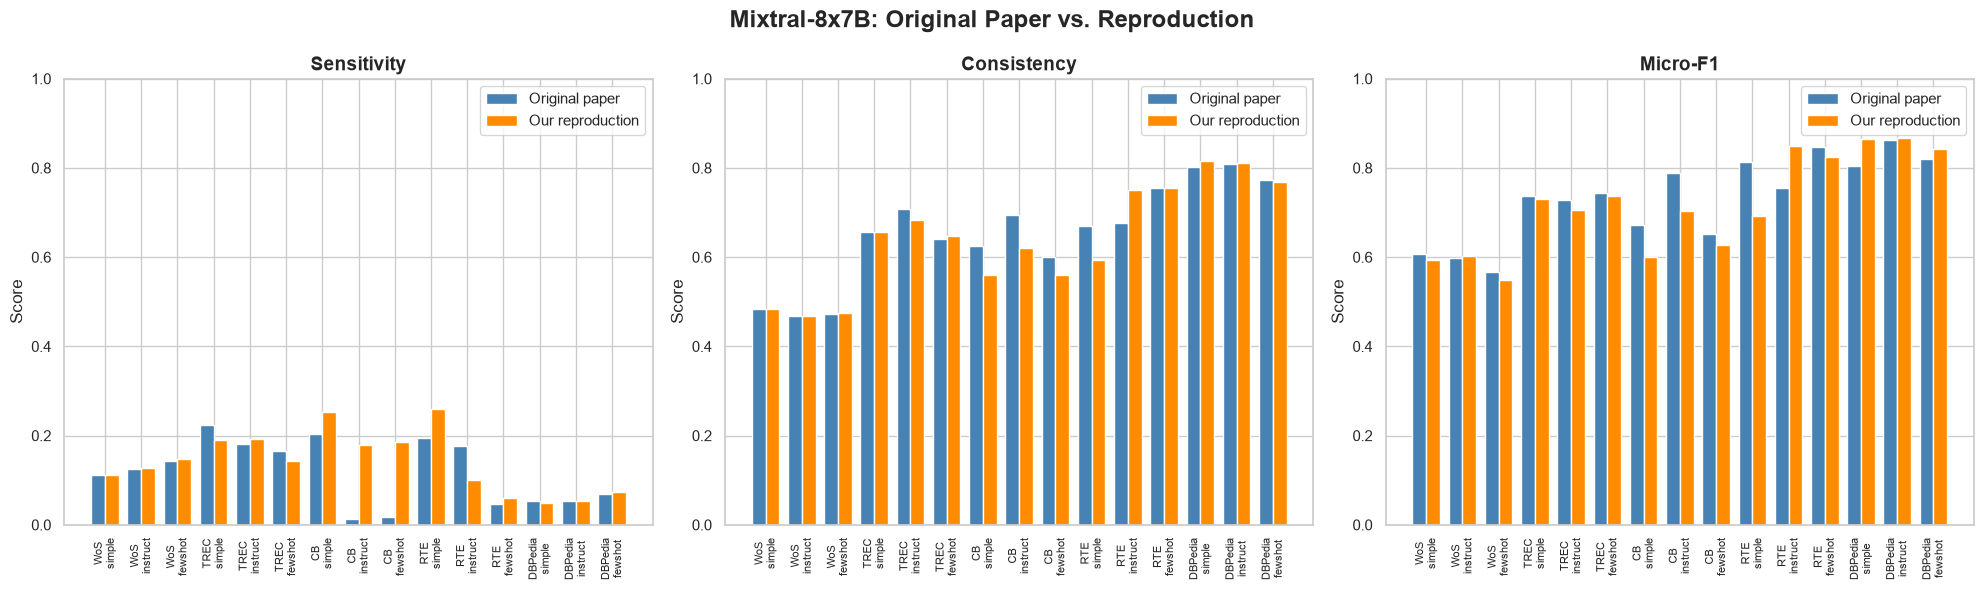

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

metrics = ["Sensitivity", "Consistency", "Micro-F1"]

for ax, metric in zip(axes, metrics):

    subset = comparison_df[
        comparison_df["Metric"] == metric
    ].copy()

    # Create labels combining dataset and strategy
    subset["Experiment"] = (
        subset["Dataset"] + "\n" + subset["Strategy"]
    )

    x = np.arange(len(subset))
    width = 0.38

    ax.bar(
        x - width / 2,
        subset["Paper"],
        width,
        label="Original paper",
        color="steelblue"
    )

    ax.bar(
        x + width / 2,
        subset["Our result"],
        width,
        label="Our reproduction",
        color="darkorange"
    )

    ax.set_title(metric, fontsize=14, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(
        subset["Experiment"],
        rotation=90,
        fontsize=8
    )
    ax.set_ylim(0, 1)
    ax.set_ylabel("Score")

    ax.legend()

plt.suptitle(
    "Mixtral-8x7B: Original Paper vs. Reproduction",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

<Figure size 900x1000 with 0 Axes>

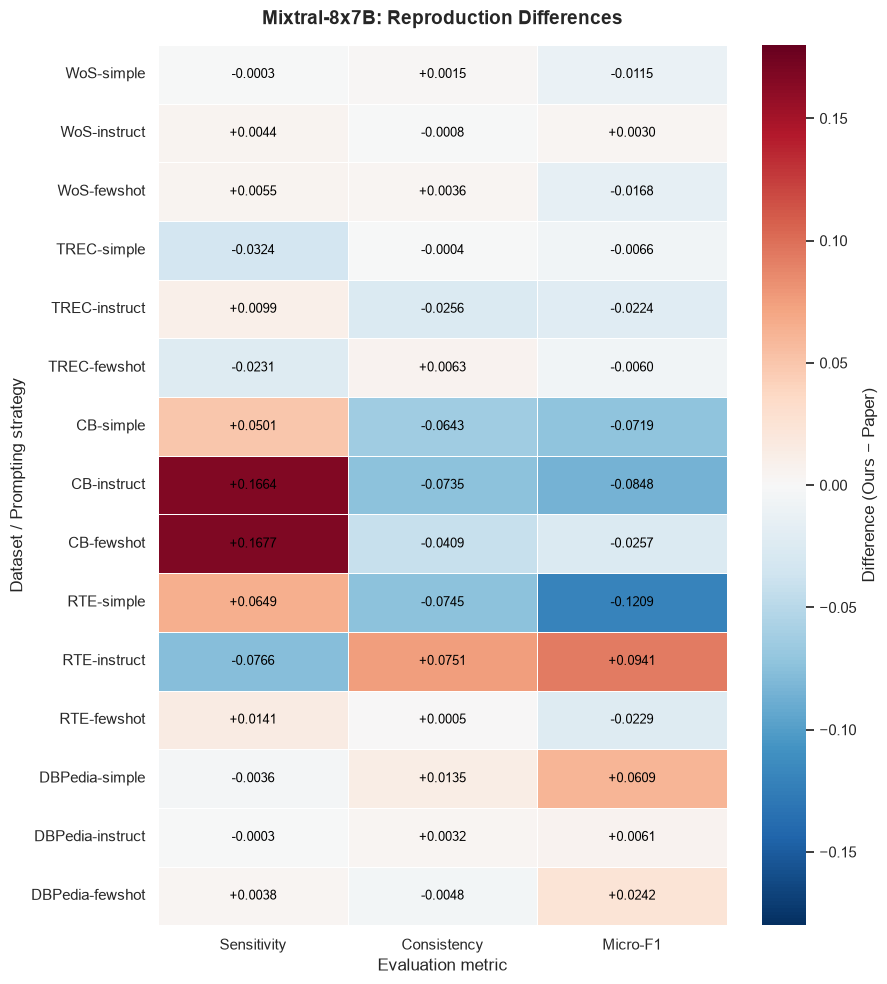

In [31]:
# difference heatmap: reproduction minus original paper

heatmap_df = comparison_df.pivot(
    index=["Dataset", "Strategy"],
    columns="Metric",
    values="Difference"
)

# consistent ordering
dataset_order = ["WoS", "TREC", "CB", "RTE", "DBPedia"]
strategy_order = ["simple", "instruct", "fewshot"]

index_order = pd.MultiIndex.from_product(
    [dataset_order, strategy_order],
    names=["Dataset", "Strategy"]
)

heatmap_df = heatmap_df.reindex(index_order)
heatmap_df = heatmap_df[
    ["Sensitivity", "Consistency", "Micro-F1"]
]

plt.figure(figsize=(9, 10))

fig, ax = plt.subplots(figsize=(9, 10))

sns.heatmap(
    heatmap_df,
    annot=False,
    cmap="RdBu_r",
    center=0,
    vmin=-0.18,
    vmax=0.18,
    linewidths=0.5,
    cbar_kws={"label": "Difference (Ours − Paper)"},
    ax=ax
)

# manually add every number
for i in range(heatmap_df.shape[0]):
    for j in range(heatmap_df.shape[1]):
        value = heatmap_df.iloc[i, j]

        ax.text(
            j + 0.5,
            i + 0.5,
            f"{value:+.4f}",
            ha="center",
            va="center",
            fontsize=9,
            color="black"
        )

ax.set_title(
    "Mixtral-8x7B: Reproduction Differences",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Evaluation metric")
ax.set_ylabel("Dataset / Prompting strategy")

plt.tight_layout()
plt.show()

In [32]:
# mean Absolute Error by dataset and evaluation metric

mae_df = (
    comparison_df
    .groupby(["Dataset", "Metric"])["Absolute difference"]
    .mean()
    .unstack()
)

mae_df = mae_df.reindex(
    ["WoS", "TREC", "CB", "RTE", "DBPedia"]
)

mae_df = mae_df[
    ["Sensitivity", "Consistency", "Micro-F1"]
]

mae_df["Overall MAE"] = mae_df.mean(axis=1)

display(mae_df.round(4))

Metric,Sensitivity,Consistency,Micro-F1,Overall MAE
Dataset,,,,
WoS,0.0034,0.0020,0.0104,0.0053
TREC,0.0218,0.0108,0.0117,0.0147
CB,0.1281,0.0596,0.0608,0.0828
RTE,0.0519,0.0500,0.0793,0.0604
DBPedia,0.0026,0.0072,0.0304,0.0134


In [33]:
ranking_results = []

for (dataset, metric), group in comparison_df.groupby(
    ["Dataset", "Metric"], sort=False
):
    # lower sensitivity is better; higher consistency/F1 is better
    ascending = metric == "Sensitivity"

    our_best = group.sort_values(
        "Our result", ascending=ascending
    ).iloc[0]["Strategy"]

    paper_best = group.sort_values(
        "Paper", ascending=ascending
    ).iloc[0]["Strategy"]

    ranking_results.append({
        "Dataset": dataset,
        "Metric": metric,
        "Our best strategy": our_best,
        "Paper best strategy": paper_best,
        "Match": our_best == paper_best
    })

ranking_df = pd.DataFrame(ranking_results)

display(ranking_df)

print(
    f"\nRanking agreement: "
    f"{ranking_df['Match'].sum()}/{len(ranking_df)}"
)

,Dataset,Metric,Our best strategy,Paper best strategy,Match
0,WoS,Sensitivity,simple,simple,True
1,WoS,Consistency,simple,simple,True
2,WoS,Micro-F1,instruct,simple,False
3,TREC,Sensitivity,fewshot,fewshot,True
4,TREC,Consistency,instruct,instruct,True
5,TREC,Micro-F1,fewshot,fewshot,True
6,CB,Sensitivity,instruct,instruct,True
7,CB,Consistency,instruct,instruct,True
8,CB,Micro-F1,instruct,instruct,True
9,RTE,Sensitivity,fewshot,fewshot,True



Ranking agreement: 12/15
